# Quickstart — como usar o package `vqc_zx`

Este notebook mostra **como usar** o package, não como ele funciona por
dentro. Não precisas de saber o que é ZX-calculus, `full_reduce` ou
sentinelas para ler isto — é a perspetiva de quem só quer:

1. registar um circuito,
2. mandar o package simplificá-lo,
3. treinar e comparar original vs. simplificado,
4. olhar para os resultados (tabelas, gráficos, os próprios circuitos).

Para os detalhes internos (como o `full_reduce` reduz o grafo, a
abordagem sentinel, porque é que o número de gates aumenta, etc.), o
notebook `tutorial_vqc_zx.ipynb` continua a ser a referência — este aqui
é só o "como se usa".

---
## Setup

In [1]:
import os
import sys

# vqc_zx/ fica ao lado de ParamZX/ na raiz do projecto
_parent = os.path.dirname(os.path.abspath(os.getcwd()))
if _parent not in sys.path:
    sys.path.insert(0, _parent)

from vqc_zx import (
    setup_pyzx,
    CircuitRegistry,
    ZXPipeline,
    GateApplicator,
)

setup_pyzx()  # adiciona ParamZX/ ao sys.path para o "import pyzx" interno funcionar

import pennylane as qml
from pennylane import numpy as np
import matplotlib.pyplot as plt

print("vqc_zx pronto a usar.")

vqc_zx pronto a usar.


---
## 1. Define os teus circuitos

Um circuito é só uma função normal do PennyLane. Regista-se num
`CircuitRegistry` com um nome, o nº de qubits e o nº de parâmetros.

In [2]:
registry = CircuitRegistry()


@registry.register("demo_cnot", n_qubits=4, n_params=8,
                    description="RX+RZ por qubit, entanglement fixo com CNOTs")
def demo_cnot(params):
    for i in range(4):
        qml.RX(params[i] * np.pi, wires=i)
    for i in range(4):
        qml.RZ(params[i + 4] * np.pi, wires=i)
    qml.CNOT(wires=[3, 2]); qml.CNOT(wires=[2, 1]); qml.CNOT(wires=[1, 0])


@registry.register("demo_crz", n_qubits=4, n_params=11,
                    description="RX+RZ por qubit, entanglement treinável com CRZ")
def demo_crz(params):
    for i in range(4):
        qml.RX(params[i] * np.pi, wires=i)
    for i in range(4):
        qml.RZ(params[i + 4] * np.pi, wires=i)
    qml.CRZ(params[8] * np.pi, wires=[3, 2])
    qml.CRZ(params[9] * np.pi, wires=[2, 1])
    qml.CRZ(params[10] * np.pi, wires=[1, 0])


print("Circuitos registados:", registry.names())
registry["demo_crz"]

Circuitos registados: ['demo_cnot', 'demo_crz']


CircuitSpec(name='demo_crz', n_qubits=4, n_params=11)

---
## 2. Cria o pipeline e corre a Fase A (otimização ZX)

O `ZXPipeline` trata de tudo: aplica a simplificação ZX a cada circuito do
registo e guarda o resultado em cache (para não repetir trabalho em
próximas execuções). Não precisas de saber como `optimize_all()`
funciona — só que, depois de correr, tens uma versão "otimizada" de cada
circuito pronta a usar.

In [3]:
pipeline = ZXPipeline(
    registry,
    cache_dir="zx_cache_tutorial/quickstart",
    results_dir="results",
    strategy="full_reduce",   # a estratégia de simplificação ZX a usar (ver secção 7)
)

pipeline.optimize_all()
print()
pipeline.print_summary()

[cache/full_reduce] demo_cnot: ops 11 → 28  params 8 → 8
[cache/full_reduce] demo_crz: ops 11 → 45  params 11 → 11

Strategy: full_reduce
circuit             ops orig  ops opt  params orig  params opt  symbolic structure
--------------------------------------------------------------------------------
demo_cnot                 11       28            8           8  ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h']
demo_crz                  11       45           11          11  ['a', 'b', 'c', 'd', 'f + j/2', '-i/2', '-j/2', '-k/2', 'h', 'e + k/2', 'g + i/2']


---
## 3. Cria um dataset

`pipeline.create_dataset` gera um dataset de classificação simples,
adaptado automaticamente ao nº de qubits dos teus circuitos.

In [4]:
# n_samples pequeno de proposito aqui so para o notebook correr rapido como demo;
# para resultados a serio usa-se 120+ (ver testes/comparacao_paramzx_batch.ipynb)
X, y = pipeline.create_dataset(n_samples=40, seed=0)
print(f"X: {X.shape}   y: {y.shape}   classe 1: {y.mean():.0%}")

X: (40, 4)   y: (40,)   classe 1: 60%


---
## 4. Corre a Fase B (treino) e vê os resultados

`run_experiment` treina **ambas** as versões de cada circuito (original e
otimizada por ZX) no mesmo dataset e devolve um dicionário com tudo —
accuracy, loss ao longo do treino, nº de parâmetros/gates de cada
versão.

In [5]:
run = pipeline.run_experiment(
    X, y,
    steps=80,
    lr=0.05,
    embedding="angle_Y",
    observable="sum_all",
    data_seed=0,
)

pipeline.print_results(run)

strategy=full_reduce  embedding=angle_Y  observable=sum_all
circuit             acc orig   acc opt    delta
--------------------------------------------------
demo_cnot              0.675     0.400   -0.275
demo_crz               0.975     0.000   -0.975


---
## 5. Visualizar os resultados

In [6]:
# Tabela de accuracy e nº de parametros/gates, direto do resultado do run_experiment
import pandas as pd

rows = []
for name, c in run["circuits"].items():
    if c.get("status") != "ok":
        continue
    rows.append({
        "circuito": name,
        "acc_original": c["accuracy_original"],
        "acc_otimizado": c["accuracy_optimized"],
        "n_params_original": c["n_params_original"],
        "n_params_otimizado": c["n_params_optimized"],
        "n_ops_original": c["n_ops_original"],
        "n_ops_otimizado": c["n_ops_optimized"],
    })

tabela = pd.DataFrame(rows)
tabela

,circuito,acc_original,acc_otimizado,n_params_original,n_params_otimizado,n_ops_original,n_ops_otimizado
0,demo_cnot,0.675,0.4,8,8,11,28
1,demo_crz,0.975,0.0,11,11,11,45


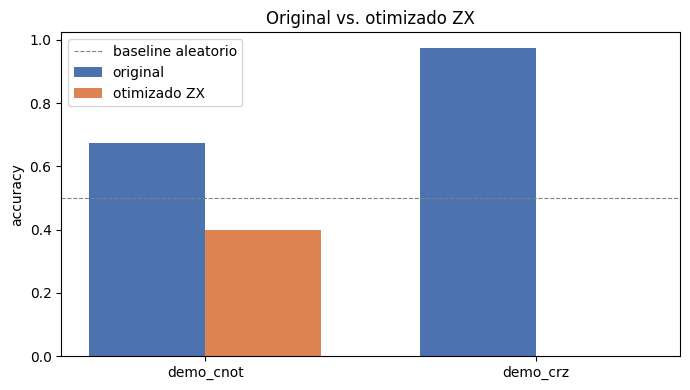

In [7]:
# Grafico de barras: accuracy original vs otimizado
fig, ax = plt.subplots(figsize=(7, 4))
x = range(len(tabela))
width = 0.35
ax.bar([i - width / 2 for i in x], tabela["acc_original"], width, label="original", color="#4C72B0")
ax.bar([i + width / 2 for i in x], tabela["acc_otimizado"], width, label="otimizado ZX", color="#DD8452")
ax.axhline(0.5, color="grey", linestyle="--", linewidth=0.8, label="baseline aleatorio")
ax.set_xticks(list(x))
ax.set_xticklabels(tabela["circuito"])
ax.set_ylabel("accuracy")
ax.set_title("Original vs. otimizado ZX")
ax.legend()
plt.tight_layout()
plt.show()

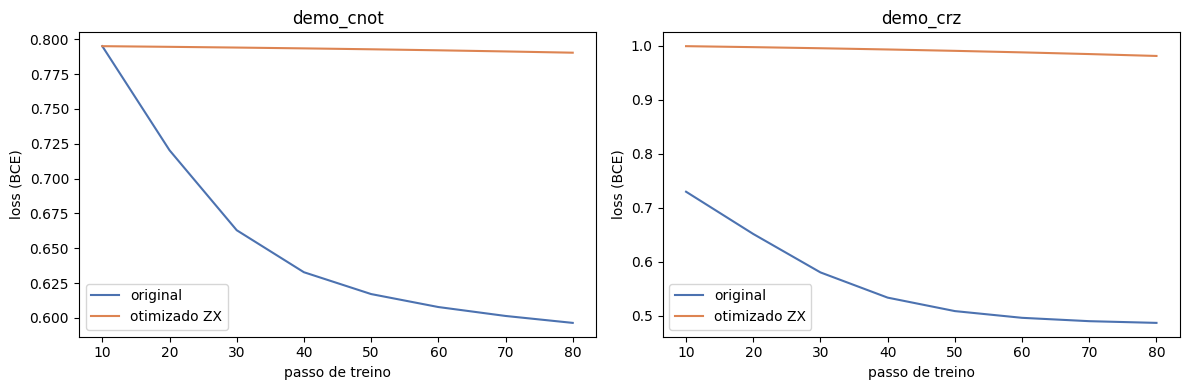

In [8]:
# Curvas de loss ao longo do treino (direto de run["circuits"][nome])
fig, axes = plt.subplots(1, len(tabela), figsize=(6 * len(tabela), 4), squeeze=False)
for ax, name in zip(axes[0], tabela["circuito"]):
    c = run["circuits"][name]
    steps_log = list(range(10, 10 * (len(c["loss_original"]) + 1), 10))
    ax.plot(steps_log, c["loss_original"], color="#4C72B0", label="original")
    ax.plot(steps_log, c["loss_optimized"], color="#DD8452", label="otimizado ZX")
    ax.set_xlabel("passo de treino")
    ax.set_ylabel("loss (BCE)")
    ax.set_title(name)
    ax.legend()
plt.tight_layout()
plt.show()

---
## 6. Guardar e reler resultados

`save_results` grava o run num JSON (agregando com runs anteriores da
mesma combinação embedding/observable/estrategia) e devolve o caminho do
ficheiro.

In [9]:
path = pipeline.save_results(run)
print("Guardado em:", path)

import json
with open(path, "r", encoding="utf-8") as f:
    saved = json.load(f)
print(f"{saved['summary']['n_runs']} run(s) guardado(s) neste ficheiro ate agora.")

Guardado em: results\angle_Y__sum_all__full_reduce.json
2 run(s) guardado(s) neste ficheiro ate agora.


---
## 7. Opções de configuração — embedding, observable, estratégia

Estas são só **parâmetros que passas** a `run_experiment` /
`ZXPipeline` — não precisas de saber como são implementados para os
usar. Alguns dos valores possíveis:

- `embedding`: `"angle_Y"` (default), `"angle_X"`, `"angle_Z"`, `"amplitude"`, `"iqp"`
- `observable`: `"sum_all"` (default), `"sum_subset"`, `"single"`, `"tensor"`/`"parity"`
- `strategy` (no `ZXPipeline`): `"full_reduce"` (default), `"clifford_simp"`, `"interior_clifford"`, `"pivot_gadget"`

Exemplo: comparar dois embeddings diferentes no mesmo circuito, sem mexer em mais nada.

In [10]:
comparacao = []
for emb in ["angle_Y", "iqp"]:
    r = pipeline.run_experiment(
        X, y, circuit_names=["demo_crz"],
        steps=60, embedding=emb, observable="sum_all", data_seed=0,
    )
    c = r["circuits"]["demo_crz"]
    comparacao.append({"embedding": emb, "acc_original": c["accuracy_original"],
                        "acc_otimizado": c["accuracy_optimized"]})

pd.DataFrame(comparacao)

,embedding,acc_original,acc_otimizado
0,angle_Y,0.950,0.000
1,iqp,0.725,0.325


---
## 8. Ver os circuitos (original vs. otimizado)

`registry[nome].fn` é a função do circuito original — dá para desenhar
com o `qml.draw_mpl` do PennyLane como qualquer outro circuito. O
circuito otimizado sai de `pipeline.cache.load_ops(nome, estrategia)`
(devolve diretamente os gates reconstruídos); o `GateApplicator` do
package sabe aplicá-los a um circuito PennyLane.

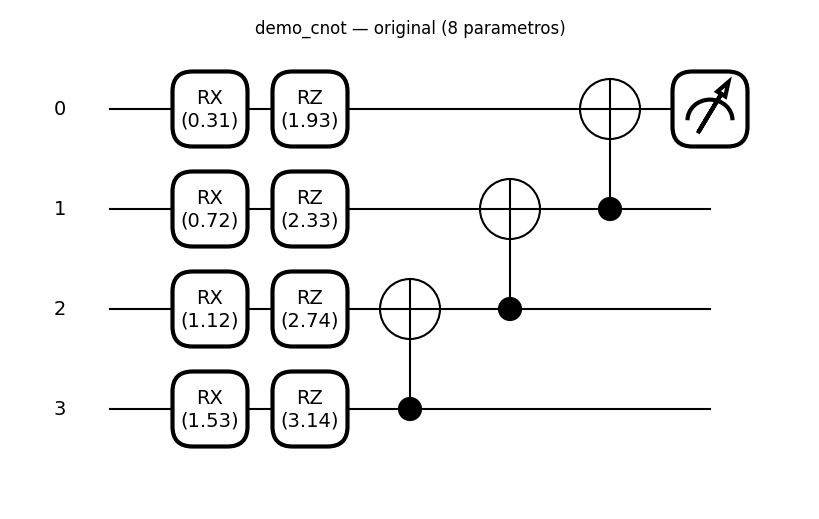

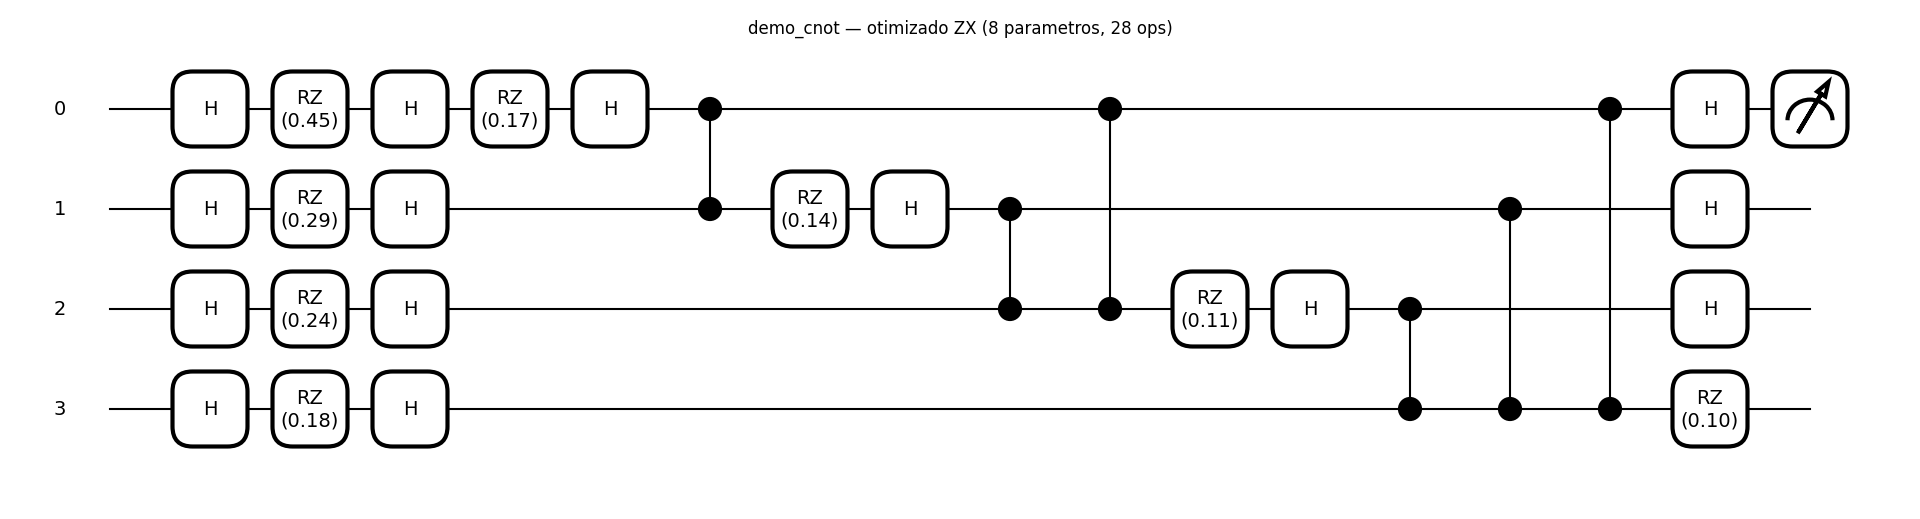

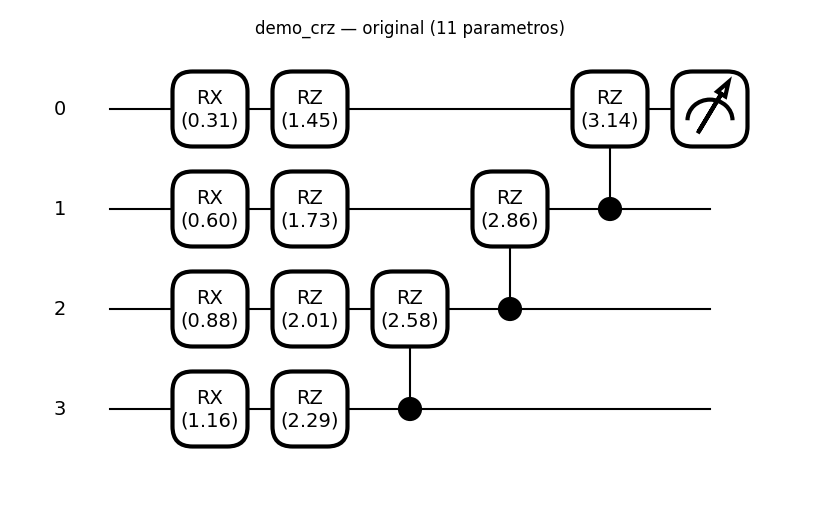

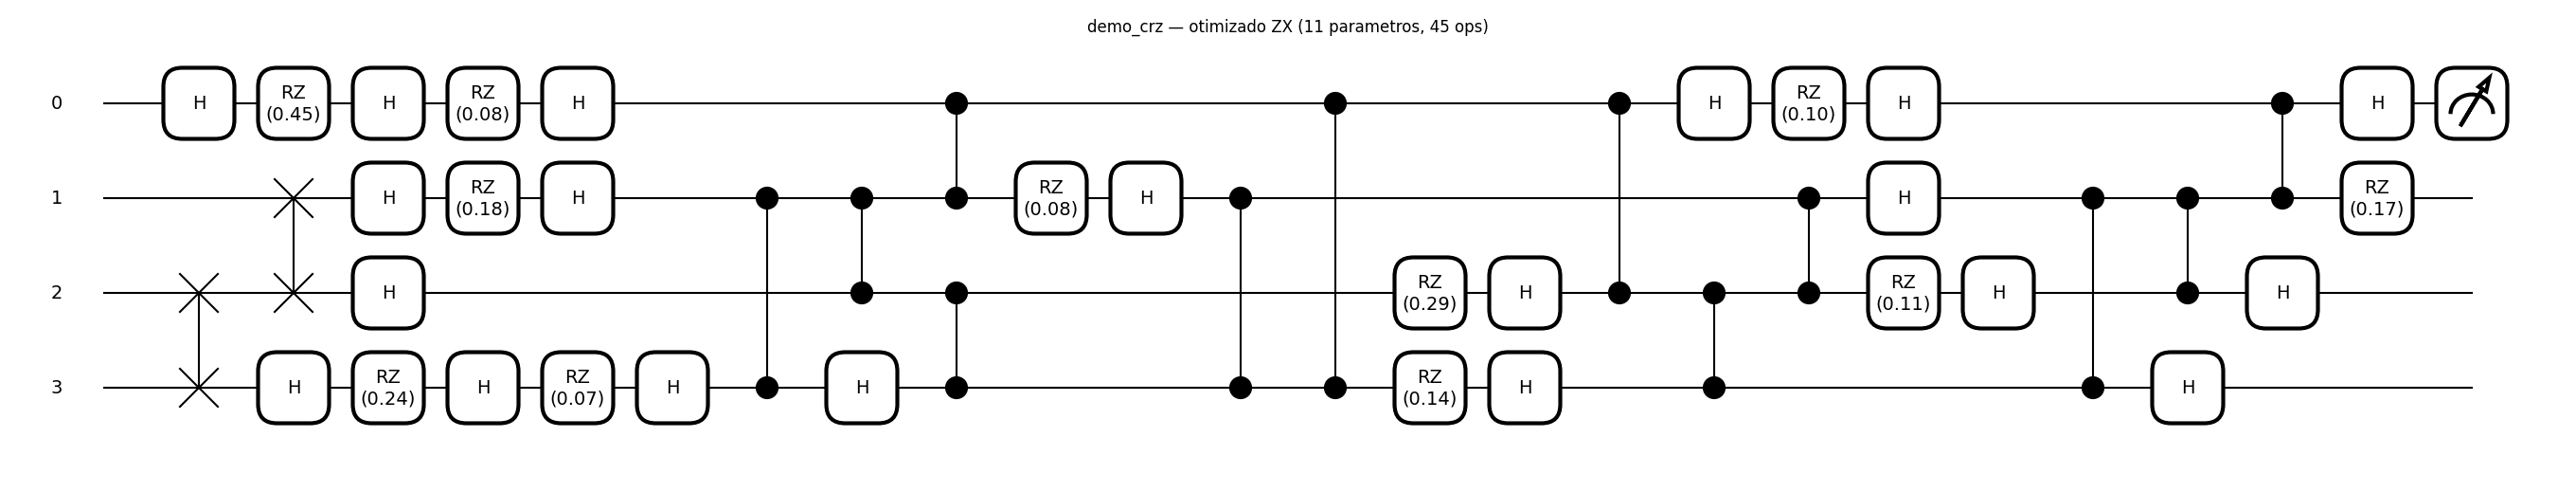

In [11]:
def desenhar(nome):
    spec = registry[nome]
    dev = qml.device("default.qubit", wires=spec.n_qubits)

    @qml.qnode(dev)
    def original(params):
        spec.fn(params)
        return qml.expval(qml.PauliZ(0))

    params = np.linspace(0.1, 1.0, spec.n_params)
    fig, _ = qml.draw_mpl(original, decimals=2)(params)
    fig.suptitle(f"{nome} — original ({spec.n_params} parametros)")
    plt.show()

    cache_data = pipeline.cache.get(nome, pipeline.strategy)
    opt_ops = pipeline.cache.load_ops(nome, pipeline.strategy)

    @qml.qnode(dev)
    def otimizado(params):
        idx = [0]
        for g in opt_ops.gates:
            GateApplicator.apply(g, params=params, param_idx=idx)
        return qml.expval(qml.PauliZ(0))

    params = np.array(cache_data["init_params_rad"])
    fig, _ = qml.draw_mpl(otimizado, decimals=2)(params)
    fig.suptitle(f"{nome} — otimizado ZX ({cache_data['n_params_optimized']} parametros, "
                 f"{cache_data['n_ops_optimized']} ops)")
    plt.show()


for nome in registry.names():
    desenhar(nome)

---
## Referência rápida

```python
from vqc_zx import (
    setup_pyzx,       # adiciona ParamZX/ ao sys.path
    CircuitRegistry,   # @registry.register(nome, n_qubits, n_params) para registar circuitos
    ZXPipeline,        # orquestra tudo: optimize_all() + run_experiment()
    VQCEvaluator,      # usado internamente por run_experiment; também dá para usar sozinho
    CacheStore,        # cache ZX em disco (pipeline.cache)
    create_dataset,    # X, y = create_dataset(n_samples, n_qubits, seed)
)

registry = CircuitRegistry()

@registry.register("nome", n_qubits=4, n_params=8)
def nome(params):
    ...

pipeline = ZXPipeline(registry, cache_dir=..., results_dir=..., strategy="full_reduce")
pipeline.optimize_all()                 # Fase A — simplificação ZX (uma vez por circuito+estrategia)
pipeline.print_summary()

X, y = pipeline.create_dataset(n_samples=120, seed=0)
run = pipeline.run_experiment(X, y, steps=200, embedding="angle_Y", observable="sum_all")
pipeline.print_results(run)
pipeline.save_results(run)              # → results/{embedding}__{observable}__{strategy}.json
```

**Onde ir a seguir:**
- `tutorial_vqc_zx.ipynb` — como o package funciona por dentro (ZX-calculus, sentinelas, porque é que CRZ e CRX se comportam de forma diferente, etc.)

---
## Experimenta tu